# Akiba expense categoriser: Naive Bayes final model

ICS 3202 Artificial Intelligence, semester project.

This notebook is the complete record of Akiba's ML module, from the raw data to the model file the app runs. It follows CRISP-DM, the standard six-phase process for data mining projects, from top to bottom.

**Final model:** Multinomial Naive Bayes, trained on 924 real expenses. Tested with 5-fold cross validation, it suggests the right category for **77.5%** of expenses (macro-F1 **0.31**). Always guessing the most common category would score 51.4%.

**To run it:** `pip install -r requirements.txt`, then open this notebook from `notebooks/` or from the repository root and run all cells.

## How the module was developed

| Stage | What we did | Where |
|---|---|---|
| Deliverable 1 | Explored the Kaggle expenses file: size, data types, missing values | `notebooks/Expenses_Exploration.ipynb` |
| CAT 2 | Naive Bayes on 5,587 synthetic rows generated from a merchant word list. It scored 97% accuracy, but the data was rejected as unrealistic | Git history |
| Base model | Rebuilt on real transactions only: cleaning, EDA, Naive Bayes, and a comparison with five other models | `notebooks/NaiveBayes_Base.ipynb` |
| Final model | All of the above in one place, the theory behind it, and checks that the exported model is the one the app runs | This notebook, and `scripts/` |

The final model is the base model with nothing changed: the same features, the same settings, the same scores.

## CRISP-DM map

| Phase | Question it answers | Section |
|---|---|---|
| 1. Business understanding | What problem are we solving, and how do we measure success? | 1 |
| 2. Data understanding | What data do we have, and what does it show? | 2 and 4 |
| 3. Data preparation | How do we clean it and turn it into model inputs? | 3 |
| 4. Modelling | Which algorithm do we use, and how does it work? | 5 |
| 5. Evaluation | How good is the model, and where does it fail? | 6 |
| 6. Deployment | How does the app use the model? | 7 |

Section 9 is a glossary of every ML term used.

## 1. Business understanding

Akiba is a personal finance app for university students. When a student records an expense, Akiba should suggest a category, so the student only has to confirm it. Akiba has nine expense categories: Food, Rent, Transport, Academic, Airtime & Data, Entertainment, Health, Personal Care and Other.

- **Supervised learning:** every training row already has its correct category (its *label*), so the model learns from examples whose answers are known.
- **Multi-class classification:** the answer is one category out of several.

**How we measure success.** *Accuracy* is the share of expenses given the right category. On its own it misleads here. Half of all expenses are Transport, so a model that always says Transport is already right 51.4% of the time. That trivial model is our *baseline*, the score any real model must beat. Our main metric is *macro-F1*, which scores each category separately and then averages them, so a small category counts as much as a big one (section 5.2).

**Limitation.** The dataset has no description or merchant name. The model can only use the amount, the date, the account and the tag. A model that reads transaction text needs labelled M-Pesa statements, which is future work.

In [1]:
import sys
from datetime import date
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.model_selection import StratifiedKFold, cross_validate, cross_val_predict
from sklearn.metrics import make_scorer, f1_score, classification_report, ConfusionMatrixDisplay

# Works from the notebooks/ folder or from the repository root
ROOT = Path("..") if Path("../data/Expenses_clean.csv").exists() else Path(".")
sys.path.insert(0, str(ROOT / "scripts"))

# The engine's own code, so this notebook and the scripts share one implementation
from features import AKIBA_CATEGORY, AMOUNT_BIN_LABELS, FEATURES, build_features
import predict as engine   # scripts/predict.py: the pure-Python inference the app uses

AKIBA_CATEGORIES = ["Food", "Rent", "Transport", "Academic", "Airtime & Data",
                    "Entertainment", "Health", "Personal Care", "Other"]
BLUE, ORANGE, GREY = "#2a78d6", "#eb6834", "#8a8984"

## 2. Data understanding

We use the expenses file of the [Kaggle Financial Transactions Dataset](https://www.kaggle.com/datasets/artemkabseu/financial-transactions-dataset-expenses-and-income). The income file from the same dataset (`data/Income_clean.csv`) is not used, because Akiba only categorises spending.

In [2]:
raw = pd.read_csv(ROOT / "data" / "Expenses_clean.csv")

print("Rows, columns:", raw.shape)
print("Missing values:", int(raw.isnull().sum().sum()))
print("Dates:", raw["date_time"].min()[:10], "to", raw["date_time"].max()[:10])
print("Times of day:", raw["date_time"].str[11:].unique().tolist())
print("Currencies:", raw["currency"].unique().tolist())
print("Accounts:", sorted(raw["account"].unique()))
print("Tags:", sorted(raw["tags"].unique()))
print("Dataset categories:", raw["category"].nunique())
print("\nData types:")
print(raw.dtypes.to_string())
raw.head()

Rows, columns: (938, 6)
Missing values: 0
Dates: 2025-01-07 to 2025-11-30
Times of day: ['00:00:00']
Currencies: ['BYN']
Accounts: ['acct_1', 'acct_2', 'acct_3']
Tags: ['2th_work', 'tag_1', 'tag_2', 'tag_3', 'tag_4', 'tag_5', 'tag_6']
Dataset categories: 14

Data types:
date_time        str
category         str
account          str
amount       float64
currency         str
tags             str


,date_time,category,account,amount,currency,tags
0,2025-11-30 00:00:00,Health,acct_1,114.0,BYN,tag_1
1,2025-11-29 00:00:00,Food,acct_1,5.0,BYN,tag_1
2,2025-11-27 00:00:00,Public transport,acct_2,1.0,BYN,tag_1
3,2025-11-27 00:00:00,Cafe,acct_1,10.0,BYN,tag_1
4,2025-11-27 00:00:00,Public transport,acct_2,1.0,BYN,tag_1


There are 938 expenses from one person, dated 7 January to 30 November 2025, all in Belarusian roubles (BYN). Each row has a date, a category, an account, an amount and a tag. The amount is the only number; the other columns are text. Nothing is missing. There is no description or merchant column, and the time is 00:00 on every row.

## 3. Data preparation

A model learns whatever is in its data, errors included, so we clean the data first. We follow the seven cleaning steps from the course notes, in order. `df` is our working copy.

### Step 1: Duplicates

In [3]:
df = raw.copy()
duplicates = df[df.duplicated()]

print("Exact duplicate rows:", len(duplicates))
print(duplicates["category"].value_counts().to_string())
df[df.duplicated(keep=False)].head(6)

Exact duplicate rows: 145
category
Public transport    138
Cafe                  4
Food                  3


,date_time,category,account,amount,currency,tags
2,2025-11-27 00:00:00,Public transport,acct_2,1.0,BYN,tag_1
4,2025-11-27 00:00:00,Public transport,acct_2,1.0,BYN,tag_1
7,2025-11-25 00:00:00,Public transport,acct_2,1.0,BYN,tag_1
8,2025-11-25 00:00:00,Public transport,acct_2,1.0,BYN,tag_1
12,2025-11-24 00:00:00,Public transport,acct_2,1.0,BYN,tag_1
13,2025-11-24 00:00:00,Public transport,acct_2,1.0,BYN,tag_1


145 rows are exact copies of another row, and 138 of them are Public transport. We keep them. The data has no times or receipt numbers, so two 1 BYN bus fares on the same day look identical even though they are two real trips. Deleting them would delete real spending.

### Step 2: Irrelevant data

In [4]:
print(df["currency"].value_counts().to_string())
df = df.drop(columns="currency")

currency
BYN    938


Every row is in BYN, so the currency column tells the model nothing. We drop it.

### Step 3: Incorrect data

In [5]:
zero = df["amount"] == 0
print("Negative amounts:", (df["amount"] < 0).sum())
print("Zero amounts:", zero.sum())
print(df.loc[zero, "category"].value_counts().to_string())

df = df[~zero]
print("Rows left:", len(df))

Negative amounts: 0
Zero amounts: 14
category
Food                7
Cafe                3
Other               2
Gifts               1
Public transport    1
Rows left: 924


No amount is negative, but 14 expenses are 0 BYN. An expense cannot cost nothing, so these rows are errors and we drop them, leaving 924.

### Step 4: Structural errors

The dataset has its own 14 categories, which do not match Akiba's. We map each one onto an Akiba category:

| Dataset category | Akiba category |
|---|---|
| Public transport, Taxi | Transport |
| Cafe, Food | Food |
| Leisure | Entertainment |
| Health | Health |
| University | Academic |
| Clothes, Bought for myself | Personal Care |
| Gifts, Loan given, Fines, Job, Other | Other |

Rows without an Akiba category: 0
Akiba categories with no rows: ['Rent', 'Airtime & Data']


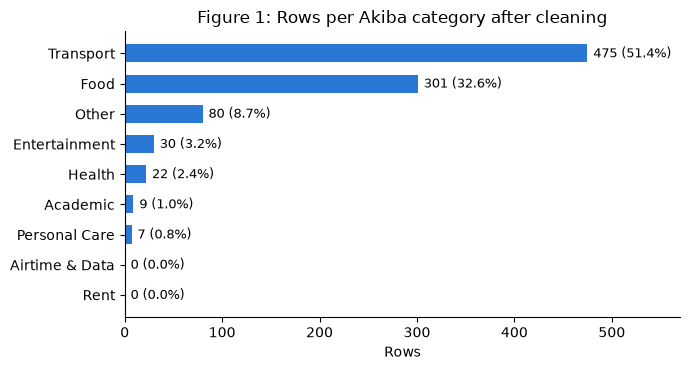

In [6]:
df["akiba_category"] = df["category"].map(AKIBA_CATEGORY)
counts = df["akiba_category"].value_counts().reindex(AKIBA_CATEGORIES, fill_value=0).sort_values()

print("Rows without an Akiba category:", df["akiba_category"].isnull().sum())
print("Akiba categories with no rows:", list(counts[counts == 0].index))

fig, ax = plt.subplots(figsize=(7, 3.8))
ax.barh(counts.index, counts.values, color=BLUE, height=0.6)
for i, n in enumerate(counts.values):
    ax.text(n + 6, i, f"{n} ({n / len(df):.1%})", va="center", fontsize=9)
ax.set_xlim(0, counts.max() * 1.2)
ax.set_xlabel("Rows")
ax.set_title("Figure 1: Rows per Akiba category after cleaning")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

Akiba's Rent and Airtime & Data categories have no examples in this dataset, so the model can learn only 7 of the 9.

### Step 5: Missing data

In [7]:
print(df.isnull().sum().to_string())

date_time         0
category          0
account           0
amount            0
tags              0
akiba_category    0


No values are missing, so there is nothing to fill in or drop.

### Step 6: Outliers

An *outlier* is a value far from the rest. We use the boxplot rule from the notes. The *IQR* (interquartile range) is the spread of the middle half of the amounts, Q3 − Q1, and any amount more than 1.5 × IQR above Q3 counts as an outlier.

In [8]:
q1, q3 = df["amount"].quantile([0.25, 0.75])
upper = q3 + 1.5 * (q3 - q1)
outliers = df[df["amount"] > upper]

print(f"Q1 = {q1}, Q3 = {q3}, upper fence = {upper:.2f} BYN")
print("Outliers:", len(outliers), "| largest:", outliers["amount"].max(), "BYN")
print(outliers["category"].value_counts().to_string())

Q1 = 1.0, Q3 = 10.25, upper fence = 24.12 BYN
Outliers: 93 | largest: 1172.0 BYN
category
Gifts                17
Other                16
Leisure              15
Health               13
Cafe                  8
Food                  8
Loan given            7
Clothes               3
Bought for myself     3
Job                   2
Taxi                  1


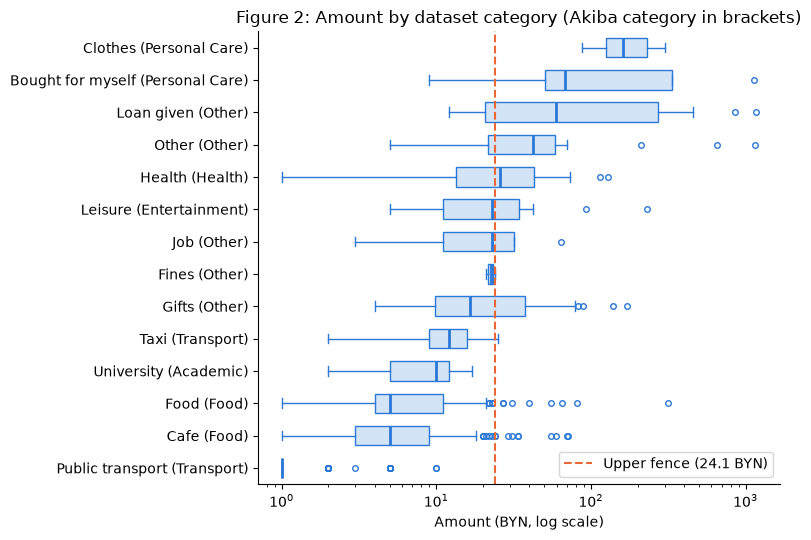

In [9]:
order = df.groupby("category")["amount"].median().sort_values().index

fig, ax = plt.subplots(figsize=(8, 5.5))
ax.boxplot([df.loc[df["category"] == c, "amount"] for c in order], orientation="horizontal",
           tick_labels=[f"{c} ({AKIBA_CATEGORY[c]})" for c in order], widths=0.6, patch_artist=True,
           boxprops={"facecolor": "#d4e4f7", "edgecolor": BLUE}, medianprops={"color": BLUE, "linewidth": 2},
           whiskerprops={"color": BLUE}, capprops={"color": BLUE},
           flierprops={"marker": "o", "markersize": 4, "markerfacecolor": "none", "markeredgecolor": BLUE})
ax.axvline(upper, color=ORANGE, linestyle="--", linewidth=1.5, label=f"Upper fence ({upper:.1f} BYN)")
ax.set_xscale("log")
ax.set_xlabel("Amount (BYN, log scale)")
ax.set_title("Figure 2: Amount by dataset category (Akiba category in brackets)")
ax.legend(loc="lower right")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

93 amounts are above the fence of 24.1 BYN, the largest being 1,172 BYN. Figure 2 shows that these are genuine large purchases: gifts, leisure, health, loans and clothes, where big amounts are normal (Clothes has a median of 161 BYN). We keep them. Step 7 puts every amount above 60 BYN into one bin, so a 1,172 BYN purchase counts the same as a 61 BYN one and cannot dominate the model.

### Step 7: Standardise and normalise

A *feature* is one input the model uses to decide. Naive Bayes learns by counting how often each value appears in each category, so every feature must be a category rather than a raw number:

- `amount` becomes 7 *bins* (ranges): [0,1], (1,2], (2,5], (5,10], (10,25], (25,60] and (60,∞) BYN.
- `date_time` becomes the day of the week, the month, and an is-weekend flag (1 for Saturday and Sunday).

`build_features()` in `scripts/features.py` applies steps 2, 3, 4 and 7 in one function. The training scripts use the same function, so the notebook and the engine cannot drift apart. The `assert` line checks that the function produces exactly the labels we built step by step above.

In [10]:
X, y = build_features(raw)
assert (y == df["akiba_category"].reset_index(drop=True)).all()

print("Rows:", len(X), "| features:", X.shape[1], "| classes:", y.nunique())
print("One-hot columns:", OneHotEncoder().fit_transform(X).shape[1])
print()
print(X["amount_bin"].value_counts().reindex(AMOUNT_BIN_LABELS).to_string())
X.head()

Rows: 924 | features: 6 | classes: 7
One-hot columns: 37

amount_bin
0-1      390
1-2       66
2-5      133
5-10     104
10-25    142
25-60     57
60+       32


,amount_bin,day_of_week,month,is_weekend,account,tags
0,60+,Sunday,11,1,acct_1,tag_1
1,2-5,Saturday,11,1,acct_1,tag_1
2,0-1,Thursday,11,0,acct_2,tag_1
3,5-10,Thursday,11,0,acct_1,tag_1
4,0-1,Thursday,11,0,acct_2,tag_1


The prepared dataset has 924 rows and 6 features (`amount_bin`, `day_of_week`, `month`, `is_weekend`, `account`, `tags`). The *target*, the value we predict, is the Akiba category, with 7 *classes* (possible answers).

**One-hot encoding** is the last step before the model. Each feature becomes one yes/no column per value. For example, `day_of_week = Monday` becomes a 1 in the Monday column and a 0 in the other six day columns. The 6 features become 37 columns. This happens inside the model pipeline in section 5.

## 4. Exploratory data analysis (EDA)

EDA means examining the clean data for patterns that will help or hurt the model.

### The classes are heavily imbalanced

Transport alone is 51.4% of the rows and Food is 32.6% (Figure 1). Health, Academic and Personal Care are each under 3%, and Personal Care has only 7 rows.

*Why it matters:* a model can score well on accuracy while getting every small category wrong, so accuracy alone is not enough.

### The amount separates the categories

In [11]:
print(df.groupby("category")["amount"].median().sort_values().to_string())

category
Public transport       1.0
Cafe                   5.0
Food                   5.0
University            10.0
Taxi                  12.0
Gifts                 16.5
Fines                 22.5
Job                   23.0
Leisure               23.0
Health                26.0
Other                 42.5
Loan given            59.0
Bought for myself     67.5
Clothes              161.0


The median Public transport fare is 1 BYN, Cafe and Food are 5 BYN, Taxi is 12 BYN and Clothes is 161 BYN (Figure 2). The mid-priced categories overlap, though: Gifts, Leisure, Health and Other all have medians between 16.5 and 42.5 BYN.

*Why it matters:* the amount bin should be the most useful feature, but on its own it cannot tell the mid-priced categories apart.

### Some tags only appear on Public transport

In [12]:
pd.crosstab(df["category"], df["tags"])

tags,2th_work,tag_1,tag_2,tag_3,tag_4,tag_5,tag_6
category,,,,,,,
Bought for myself,0,4,0,0,0,0,0
Cafe,0,166,0,0,0,0,0
Clothes,0,3,0,0,0,0,0
Fines,0,2,0,0,0,0,0
Food,0,135,0,0,0,0,0
Gifts,0,40,0,0,0,0,0
Health,0,22,0,0,0,0,0
Job,2,3,0,0,0,0,0
Leisure,0,30,0,0,0,0,0


tag_2, tag_3, tag_4 and tag_6 appear only on Public transport, on 273 of its 413 rows. tag_1 appears in every category.

*Why it matters:* one of those four tags almost guarantees Transport, but tags give no help in telling the other categories apart.

### The duplicates are genuine repeat purchases

In [13]:
repeats = df[df.duplicated(keep=False)]
print(repeats.groupby("category")["amount"].agg(["size", "min", "max"]).to_string())

                  size  min  max
category                        
Cafe                 6  3.0  5.0
Food                 6  1.0  6.0
Public transport   240  1.0  5.0


Almost every repeated row is a Public transport fare of 1 to 5 BYN, on a day with other identical fares. That is what several bus or metro trips in one day look like. The few Cafe and Food repeats are small amounts too.

*Why it matters:* keeping them gives Transport its true weight in this person's spending.

### Dates only, no times

Every `date_time` is at 00:00, so the time of day is unavailable, though it could have helped (a lunch versus a late-night taxi).

*Why it matters:* the model can use only the day, month and weekend flag from the date.

## 5. Modelling

### 5.1 How Naive Bayes works

Naive Bayes picks the category that is most probable for an expense, given its features. It is based on Bayes' rule:

$$P(\text{category} \mid \text{features}) \;\propto\; P(\text{category}) \times P(\text{features} \mid \text{category})$$

In words, a category's score for an expense is the product of two things (∝ means "is proportional to"):

- **The prior**, $P(\text{category})$: how common the category is overall. Transport is 51% of all rows, so it starts far ahead. Personal Care is under 1%.
- **The likelihood**, $P(\text{features} \mid \text{category})$: how typical this expense's features are for that category. For example, Transport expenses are very often 0 to 1 BYN.

**Why "naive":** the model assumes the features are independent once the category is known. The likelihood is then simply the per-feature probabilities multiplied together:

$$P(\text{features} \mid c) = P(\text{amount bin} \mid c) \times P(\text{day} \mid c) \times \dots \times P(\text{tag} \mid c)$$

This is rarely exactly true (day of week and is-weekend are clearly linked), but it keeps the model simple and fast, and it works with little data.

**Multinomial** Naive Bayes learns these probabilities by counting how often each one-hot column is 1 among a category's training rows.

**Smoothing (alpha).** A feature value that never appeared with a category in training would get probability 0. That 0 would wipe out the whole product and rule the category out over a single unseen value. Smoothing adds `alpha` to every count, so no probability is ever exactly 0. We use the default, alpha = 1.

**Log-probabilities.** Multiplying many small probabilities gives numbers too tiny for a computer to store accurately. So the model adds their logarithms instead, and the highest total wins. Section 7.3 shows this calculation on a real expense.

**Why we chose it:** Naive Bayes is the base model from our proposal. It trains in milliseconds, and it gives a probability for every category, which Akiba uses as its confidence. The trained model is just a small table of probabilities, so the app can run it without any ML library.

### 5.2 Base model and how we test it

- **Pipeline:** one-hot encoding followed by `MultinomialNB()`. With `handle_unknown="ignore"`, a value never seen in training (such as a new tag) is skipped rather than causing an error.
- **Cross validation:** scoring a model on data it trained on would overstate its quality, like marking a student on the exact questions they revised. 5-fold cross validation splits the rows into 5 equal parts (*folds*). It trains on 4 folds, tests on the 5th, and repeats until every fold has been the test fold once, then averages the 5 scores.
- **Stratified:** every fold keeps the same category proportions as the full data. This matters because Personal Care has only 7 rows.

How we score it, for one category such as Food:

- **Precision:** of the expenses the model labelled Food, the share that really were Food.
- **Recall:** of the real Food expenses, the share the model found.
- **F1:** a single score combining precision and recall (their harmonic mean). It runs from 0 (nothing right) to 1 (perfect).
- **Macro-F1:** the average F1 over the 7 categories, each counting equally. Our proposal (section 3.12) names it the primary metric, because with imbalanced classes accuracy hides weak categories.

In [14]:
folds = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
# A category the model never predicts gets precision 0 instead of a warning
scoring = {"accuracy": "accuracy",
           "macro_f1": make_scorer(f1_score, average="macro", zero_division=0)}

def pipeline(model):
    return Pipeline([("onehot", OneHotEncoder(handle_unknown="ignore")), ("model", model)])

nb_cv = cross_validate(pipeline(MultinomialNB()), X, y, cv=folds, scoring=scoring)

print(f"Accuracy: {nb_cv['test_accuracy'].mean():.3f} ± {nb_cv['test_accuracy'].std():.3f}")
print(f"Macro-F1: {nb_cv['test_macro_f1'].mean():.3f} ± {nb_cv['test_macro_f1'].std():.3f}")
print(f"Baseline (always predict Transport): {(y == 'Transport').mean():.3f}")

Accuracy: 0.775 ± 0.007
Macro-F1: 0.309 ± 0.007
Baseline (always predict Transport): 0.514


Naive Bayes is right on 77.5% of expenses it has never seen, well above the 51.4% baseline. The ± is the standard deviation across the 5 folds: how much the score moves when the test rows change. At 0.007 it is small, so the result is stable. The macro-F1 is only 0.31, though. Section 6 shows why.

### 5.3 Model comparison

We compare Naive Bayes with five other algorithms from the course. All six get the same 6 one-hot features and the same 5 folds, so any difference comes from the algorithm alone.

| Model | The idea in one line |
|---|---|
| Logistic Regression | Gives each one-hot column a weight per category and turns the weighted sums into probabilities |
| Decision Tree | A flowchart of yes/no questions about the features |
| K-Nearest Neighbours (KNN) | Copies the most common category among the 5 most similar training expenses |
| Random Forest | Many decision trees, each trained on a random sample of the rows, that vote |
| Gradient Boosting | Small trees built one after another, each correcting the mistakes of those before it |

**Overfitting** is when a model memorises its training data instead of learning general patterns. It then scores much higher on the rows it trained on than on new rows. To check for it, we also record each model's accuracy on its own training folds.

In [15]:
models = {
    "Naive Bayes": MultinomialNB(),
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "K-Nearest Neighbours": KNeighborsClassifier(),
    "Random Forest": RandomForestClassifier(random_state=42),
    "Gradient Boosting": GradientBoostingClassifier(random_state=42),
}

rows = []
for name, model in models.items():
    cv = cross_validate(pipeline(model), X, y, cv=folds, scoring=scoring, return_train_score=True)
    rows.append({"model": name,
                 "accuracy": cv["test_accuracy"].mean(), "accuracy_std": cv["test_accuracy"].std(),
                 "macro_f1": cv["test_macro_f1"].mean(), "macro_f1_std": cv["test_macro_f1"].std(),
                 "train_accuracy": cv["train_accuracy"].mean()})

results = pd.DataFrame(rows).set_index("model")
results.round(3)

,accuracy,accuracy_std,macro_f1,macro_f1_std,train_accuracy
model,,,,,
Naive Bayes,0.775,0.007,0.309,0.007,0.794
Logistic Regression,0.782,0.007,0.328,0.025,0.807
Decision Tree,0.733,0.022,0.322,0.043,0.930
K-Nearest Neighbours,0.739,0.007,0.297,0.022,0.819
Random Forest,0.756,0.018,0.333,0.017,0.930
Gradient Boosting,0.769,0.016,0.348,0.043,0.888


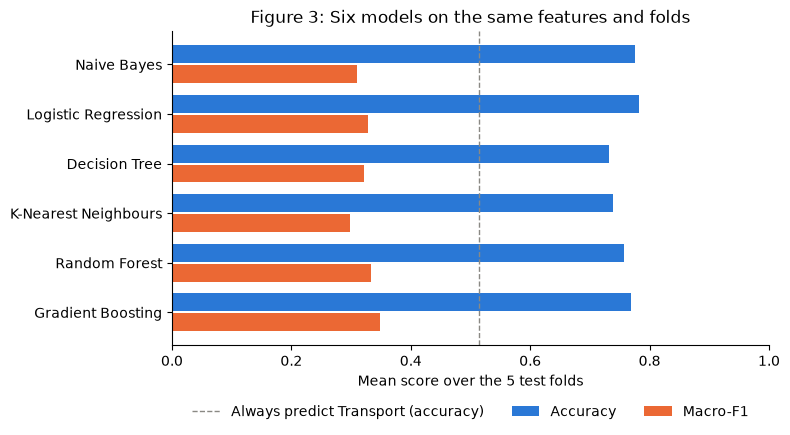

In [16]:
fig, ax = plt.subplots(figsize=(8, 4.5))
positions = range(len(results))
ax.barh([p - 0.2 for p in positions], results["accuracy"], height=0.36, color=BLUE, label="Accuracy")
ax.barh([p + 0.2 for p in positions], results["macro_f1"], height=0.36, color=ORANGE, label="Macro-F1")
ax.axvline((y == "Transport").mean(), color=GREY, linestyle="--", linewidth=1,
           label="Always predict Transport (accuracy)")
ax.set_yticks(list(positions), results.index)
ax.invert_yaxis()
ax.set_xlim(0, 1)
ax.set_xlabel("Mean score over the 5 test folds")
ax.set_title("Figure 3: Six models on the same features and folds")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.15), ncol=3, frameon=False)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

All six models score between 0.73 and 0.78 accuracy and between 0.30 and 0.35 macro-F1, and all of them beat the baseline. Logistic Regression has the best accuracy (0.782) and Gradient Boosting the best macro-F1 (0.348). The gaps to Naive Bayes are only about the size of the fold-to-fold spread, so no model is clearly better.

The Decision Tree and Random Forest score 0.930 on their training folds but only 0.733 and 0.756 on unseen folds, so they overfit. Naive Bayes has the smallest gap (0.794 train, 0.775 test).

**Decision:** we keep Naive Bayes. On this data it matches the others, it barely overfits, and it exports to a small JSON file the app can run.

### 5.4 Regularisation

A model that is too simple *underfits*: it scores low on both training and test data. A model that is too complex overfits. *Regularisation* penalises complexity to find the balance. In Logistic Regression, the setting `C` controls it. A small `C` means strong regularisation and a simpler model. A setting like this, chosen by us rather than learnt from the data, is called a *hyperparameter*.

In [17]:
sweep = []
for C in [0.01, 0.1, 1, 10, 100]:
    cv = cross_validate(pipeline(LogisticRegression(C=C, max_iter=1000)), X, y, cv=folds,
                        scoring="accuracy", return_train_score=True)
    sweep.append({"C": C, "train_accuracy": cv["train_score"].mean(), "test_accuracy": cv["test_score"].mean()})

sweep = pd.DataFrame(sweep).set_index("C")
sweep["gap"] = sweep["train_accuracy"] - sweep["test_accuracy"]
sweep.round(3)

,train_accuracy,test_accuracy,gap
C,,,
0.01,0.738,0.733,0.005
0.10,0.790,0.777,0.013
1.00,0.807,0.782,0.024
10.00,0.814,0.774,0.040
100.00,0.816,0.771,0.046


At C = 0.01 the model underfits: train and test accuracy are both low. Test accuracy peaks at C = 1, the default. As C grows to 100, train accuracy keeps rising while test accuracy falls, so the gap widens and the model starts to overfit. With only 6 categorical features the overfitting stays mild. These features do not overfit easily, which supports keeping a simple model like Naive Bayes.

## 6. Evaluation

To see where Naive Bayes goes wrong, every row is predicted once by the fold model that did not train on it (`cross_val_predict`). We then compare those predictions with the true categories.

A **confusion matrix** has the true categories as rows and the predicted ones as columns. The diagonal counts correct answers. Every other cell is a mistake, and its column shows which category the expense was confused with.

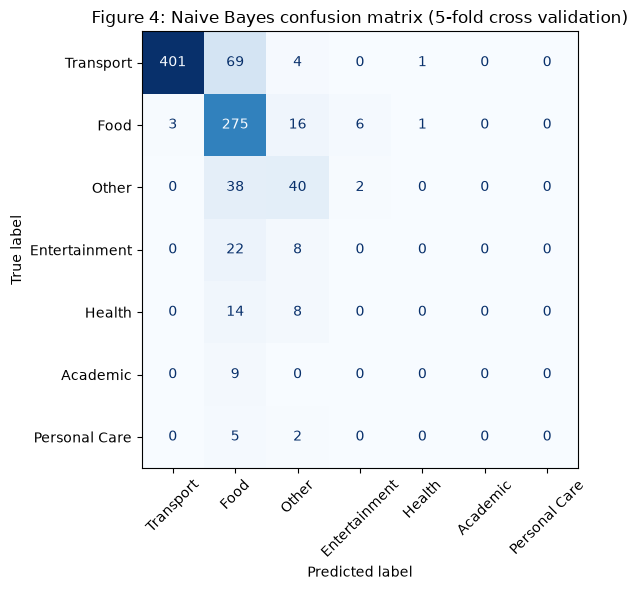

               precision    recall  f1-score   support

    Transport      0.993     0.844     0.912       475
         Food      0.637     0.914     0.750       301
        Other      0.513     0.500     0.506        80
Entertainment      0.000     0.000     0.000        30
       Health      0.000     0.000     0.000        22
     Academic      0.000     0.000     0.000         9
Personal Care      0.000     0.000     0.000         7

     accuracy                          0.775       924
    macro avg      0.306     0.323     0.310       924
 weighted avg      0.762     0.775     0.757       924



In [18]:
predicted = cross_val_predict(pipeline(MultinomialNB()), X, y, cv=folds)
labels = y.value_counts().index  # largest category first

fig, ax = plt.subplots(figsize=(7, 6))
ConfusionMatrixDisplay.from_predictions(y, predicted, labels=labels, cmap="Blues", colorbar=False,
                                        xticks_rotation=45, ax=ax)
ax.set_title("Figure 4: Naive Bayes confusion matrix (5-fold cross validation)")
plt.tight_layout()
plt.show()

print(classification_report(y, predicted, labels=labels, digits=3, zero_division=0))

The pattern is high accuracy with a low macro-F1.

- **The big categories work.** Transport has a precision of 0.993: when the model says Transport, it is almost always right. Food has a recall of 0.914: it finds almost every Food expense.
- **Other is about half right**, with an F1 of 0.51.
- **The four small categories are never predicted correctly.** Entertainment, Health, Academic and Personal Care all have a recall of 0, and their expenses are labelled Food or Other instead. Their priors are tiny (Academic is 1% of rows). The amount, date, account and tag do not separate them strongly enough to overcome that.

Transport also hides a weak spot:

In [19]:
taxi = (df["category"] == "Taxi").to_numpy()
print("Taxi rides:", taxi.sum(), "| predicted as:")
print(pd.Series(predicted[taxi]).value_counts().to_string())

Taxi rides: 62 | predicted as:
Food      57
Other      4
Health     1


All 62 taxi rides are missed, and 57 of them are labelled Food. A 5 to 25 BYN expense on acct_1 with tag_1 looks just like a cafe bill. The model really recognises bus and metro fares, not transport in general.

Our proposal's literature review describes the same trap: a categoriser with 76% accuracy that hid a macro-F1 of 0.40. Our 77.5% accuracy with a macro-F1 of 0.31 is the same pattern, which is why macro-F1 is the number we track.

## 7. Deployment

The Akiba app does not run scikit-learn. The engine ships in three steps:

1. `scripts/train.py` fits the model on all 924 rows.
2. `scripts/export.py` saves its probability tables to `out/model.json`.
3. `scripts/predict.py` reads `out/model.json` and classifies an expense in plain Python, which is called *inference*.

This section checks each link in that chain.

### 7.1 The final model is the shipped model

Cross validation was only for measuring quality. The final model is trained once on all 924 rows, exactly as `scripts/train.py` does. We then check that the committed `out/model.json` contains this exact model.

In [20]:
final = pipeline(MultinomialNB()).fit(X, y)
onehot, nb = final.named_steps["onehot"], final.named_steps["model"]
shipped = engine.load(engine.MODEL)

assert shipped["classes"] == nb.classes_.tolist()
assert shipped["alpha"] == nb.alpha
assert shipped["features"] == FEATURES
assert shipped["categories"] == {name: values.tolist() for name, values in zip(FEATURES, onehot.categories_)}
assert np.allclose(shipped["class_log_prior"], nb.class_log_prior_)
assert np.allclose(shipped["feature_log_prob"], nb.feature_log_prob_)

print(f"out/model.json matches the final model: {len(nb.classes_)} classes, "
      f"{nb.feature_log_prob_.shape[1]} one-hot columns, alpha = {nb.alpha}")
print("Classes:", ", ".join(nb.classes_))

out/model.json matches the final model: 7 classes, 37 one-hot columns, alpha = 1.0
Classes: Academic, Entertainment, Food, Health, Other, Personal Care, Transport


### 7.2 The app's pure-Python inference gives the same answers

`predict.py` rebuilds the 6 features and adds up the log-probabilities from `out/model.json` by hand. We run it on all 924 expenses and compare its probabilities with scikit-learn's.

In [21]:
expenses = raw[raw["amount"] > 0].reset_index(drop=True)   # the same rows as X
sklearn_proba = final.predict_proba(X)

largest_diff, same_label = 0.0, 0
for i, row in expenses.iterrows():
    values = engine.features(row["amount"], date.fromisoformat(row["date_time"][:10]),
                             row["account"], row["tags"], shipped)
    ranked, _ = engine.predict(values, shipped)
    mine = dict(ranked)
    largest_diff = max(largest_diff, max(abs(mine[c] - p) for c, p in zip(nb.classes_, sklearn_proba[i])))
    same_label += ranked[0][0] == nb.classes_[sklearn_proba[i].argmax()]

print(f"Same predicted category on {same_label}/{len(expenses)} expenses")
print(f"Largest probability difference: {largest_diff:.1e}")
assert same_label == len(expenses) and largest_diff < 1e-6

Same predicted category on 924/924 expenses
Largest probability difference: 2.3e-15


The pure-Python engine agrees with scikit-learn on every expense. The differences are only floating-point rounding, so the app's suggestions are exactly this model's.

### 7.3 One suggestion, step by step

This is the section 5.1 calculation on a typical taxi fare: 12 BYN on Tuesday 10 June 2025, from acct_1, with tag_1. Each category starts from its log prior and adds the log-probability of each feature value. The highest total wins, and converting the totals back to probabilities gives the confidence.

In [22]:
def explain(amount, day, account, tag):
    # Per-category log-scores for one expense, laid out like predict.py adds them up
    values = engine.features(amount, date.fromisoformat(day), account, tag, shipped)
    steps, column = {"log prior": shipped["class_log_prior"]}, 0
    for name in shipped["features"]:
        seen = shipped["categories"][name]
        j = column + seen.index(values[name])
        steps[f"+ log P({name} = {values[name]})"] = [row[j] for row in shipped["feature_log_prob"]]
        column += len(seen)
    table = pd.DataFrame(steps, index=shipped["classes"]).T
    table.loc["= total log-score"] = table.sum()
    ranked, _ = engine.predict(values, shipped)
    table.loc["probability"] = pd.Series(dict(ranked))
    return table[[c for c, _ in ranked]]   # most likely category first

explain(12, "2025-06-10", "acct_1", "tag_1").round(2)

,Food,Health,Other,Transport,Entertainment,Academic,Personal Care
log prior,-1.12,-3.74,-2.45,-0.67,-3.43,-4.63,-4.88
+ log P(amount_bin = 10-25),-3.41,-3.05,-3.11,-4.28,-2.89,-3.12,-4.37
+ log P(day_of_week = Tuesday),-3.63,-3.34,-3.54,-3.32,-4.28,-3.41,-3.27
+ log P(month = 6),-4.15,-3.18,-5.15,-4.14,-3.99,-4.51,-4.37
+ log P(is_weekend = 0),-2.05,-2.13,-2.17,-1.96,-2.29,-2.31,-2.42
+ log P(account = acct_1),-2.32,-2.09,-2.12,-3.86,-2.20,-2.43,-2.29
+ log P(tags = tag_1),-1.81,-1.99,-1.88,-2.66,-1.95,-2.21,-2.29
= total log-score,-18.49,-19.52,-20.42,-20.89,-21.03,-22.63,-23.90
probability,0.59,0.21,0.09,0.05,0.05,0.01,0.00


Transport starts with the best log prior (−0.67), because it is the most common category. It then loses ground on three features: 10–25 BYN, acct_1 and tag_1 are all much less common for Transport than for Food, because most Transport rows are 1 BYN bus fares. Food ends with the highest total and a probability of 0.59, while Transport finishes fourth at 0.05. The answer is wrong, and it is exactly the taxi weakness from section 6.

### 7.4 When Akiba asks the student to confirm

If the top probability is below 60% (`LOW_CONFIDENCE` in `predict.py`), Akiba asks the student to choose the category instead of filling it in. The taxi fare above, at 59%, would be flagged. Using the cross-validated probabilities, we check that the flagged suggestions really are the risky ones.

In [23]:
proba = cross_val_predict(pipeline(MultinomialNB()), X, y, cv=folds, method="predict_proba")
confidence = proba.max(axis=1)
correct = nb.classes_[proba.argmax(axis=1)] == y.to_numpy()
low = confidence < engine.LOW_CONFIDENCE

print(f"Suggestions below {engine.LOW_CONFIDENCE:.0%} confidence: {low.mean():.1%} of expenses")
print(f"Accuracy of confident suggestions: {correct[~low].mean():.1%}")
print(f"Accuracy of low-confidence suggestions: {correct[low].mean():.1%}")

Suggestions below 60% confidence: 16.9% of expenses
Accuracy of confident suggestions: 85.2%
Accuracy of low-confidence suggestions: 39.7%


About one suggestion in six is flagged. Those are right less than half the time, while the confident ones are right about 85% of the time. The rule sends the student exactly the expenses the model is unsure of.

### 7.5 Running the engine

```bash
python scripts/train.py             # cross validation, then fit on all rows -> out/metrics.json, out/categoriser.pkl
python scripts/export.py            # -> out/model.json, out/parity.json
python scripts/predict.py --check   # pure-Python inference matches scikit-learn on 25 saved rows
python scripts/predict.py --amount 12 --date 2025-06-10 --account acct_1 --tag tag_1
```

## 8. Conclusions and limitations

Trained on real transactions, Naive Bayes suggests the right Akiba category for 77.5% of expenses, against 51.4% for always guessing Transport. That accuracy comes almost entirely from Transport and Food. The macro-F1 of 0.31 shows that the smaller categories are not learned. Five other models do no better, so the limit is the data rather than the algorithm. The exported model runs in plain Python and matches scikit-learn exactly. The 60% confidence rule flags the suggestions most likely to be wrong.

Limitations:

- The data is one person's spending, in Belarus and in BYN, so it may not generalise to Kenyan students.
- There is no transaction text, only the amount, date, account and tag.
- Only 7 of Akiba's 9 categories appear: Rent and Airtime & Data are missing.
- The small categories have very few rows (Personal Care 7, Academic 9), and taxi rides are mistaken for Food.

Next steps:

- Collect donated, labelled M-Pesa statements, as described in the proposal, so the model can learn from the transaction text of Kenyan students. `scripts/extract.py` already reads and anonymises statement PDFs for this.
- Update the app's TypeScript categoriser to read the current `out/model.json` format.

## 9. Glossary

| Term | Meaning |
|---|---|
| Accuracy | Share of expenses given the right category |
| Alpha (smoothing) | A small number added to every count so no probability is exactly 0; default 1 |
| Baseline | A trivial reference model (always predict Transport) that any real model must beat |
| Bin | A range of values treated as one category, such as 10 to 25 BYN |
| Class / label / target | The thing we predict: the Akiba category |
| Confusion matrix | A table of true against predicted categories; the diagonal holds the correct answers |
| CRISP-DM | The standard six-phase process for data mining projects, which this notebook follows |
| Cross validation (k-fold) | Train on k−1 parts of the data, test on the remaining part, rotate, and average the scores |
| EDA | Exploratory data analysis: looking at the data for patterns before modelling |
| F1 score | A single 0 to 1 score combining precision and recall |
| Feature | One input the model uses, such as the amount bin or the day of the week |
| Hyperparameter | A setting chosen by us rather than learnt from the data, such as `alpha` or `C` |
| Imbalanced classes | Some categories have far more rows than others |
| Inference | Using a trained model to classify a new expense |
| IQR | Interquartile range, Q3 − Q1: the spread of the middle half of the values |
| Likelihood | How typical an expense's features are for a category, P(features given category) |
| Log-probability | The logarithm of a probability; adding logs avoids numbers too small to store |
| Macro-F1 | The F1 score averaged over all categories, each counting equally |
| Multi-class classification | Predicting one answer out of more than two categories |
| Naive Bayes | A classifier that applies Bayes' rule and assumes the features are independent |
| One-hot encoding | Turning a feature into one yes/no column per value |
| Outlier | A value far from the rest of the data |
| Overfitting | Memorising the training data: high training score, much lower test score |
| Pipeline | Steps chained together (here, one-hot encoding then the model) so they are always applied in the same order |
| Precision | Of the expenses labelled a category, the share that really belong to it |
| Prior | How common a category is before looking at the expense's features |
| Recall | Of the expenses that really belong to a category, the share the model found |
| Regularisation | Penalising complexity so a model does not overfit |
| Stratified | Every fold keeps the same category proportions as the full data |
| Supervised learning | Learning from examples whose correct answers (labels) are known |
| Underfitting | A model too simple to capture the patterns: low scores on training and test data |